# LangChain MCP Adapters

https://github.com/langchain-ai/langchain-mcp-adapters


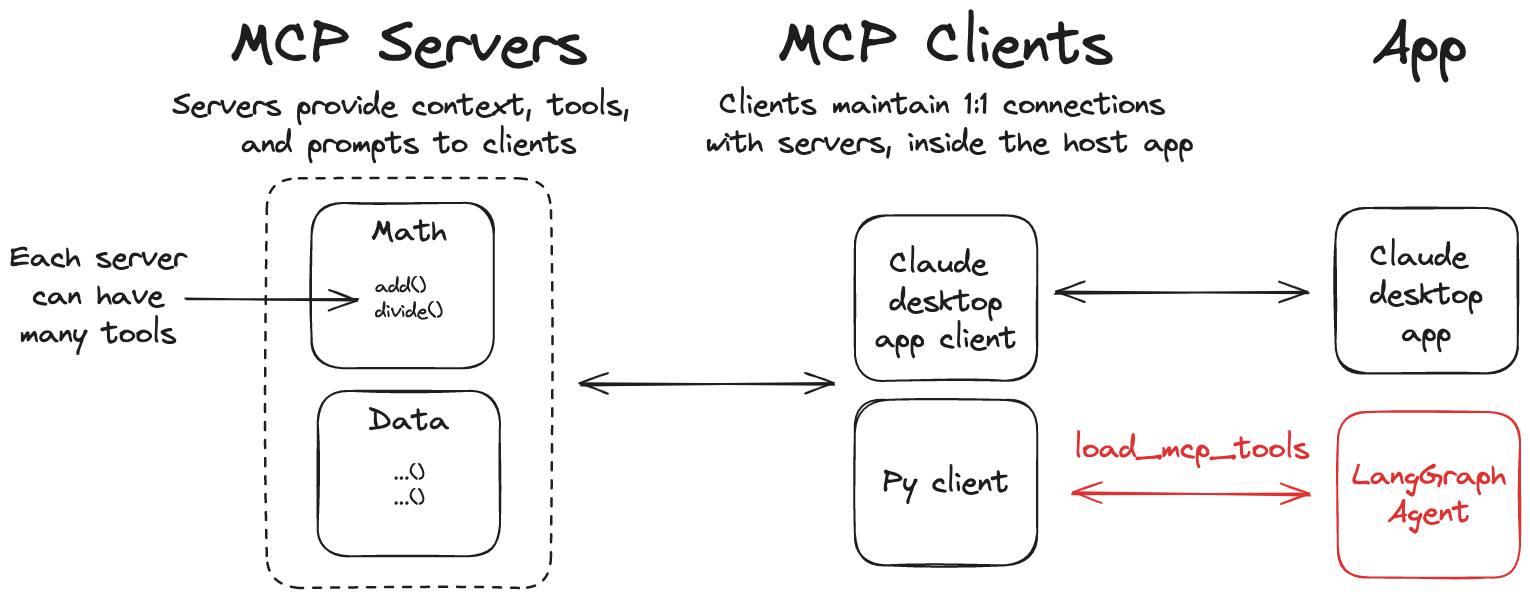

# 세팅

In [1]:
! uv pip install langchain-mcp-adapters

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 16ms


In [2]:
! uv pip install pywin32

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 10ms


In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


# [예제1] MCP server  & MCP Client

##   create an MCP server 

can add and multiply numbers.

In [ ]:
# math_server.py
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Math"라는 이름의 MCP 서버 인스턴스를 생성
mcp = FastMCP("Math")

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def add(a: int, b: int) -> int:
    """Add two numbers"""  # 두 숫자를 더하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 더한 결과를 반환
    return a + b

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def multiply(a: int, b: int) -> int:
    """Multiply two numbers"""  # 두 숫자를 곱하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 곱한 결과를 반환
    return a * b

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # 서버 시작 안내 메시지를 콘솔에 출력
    print("MCP server started and waiting for clients...")
    # streamable-http 전송 방식으로 MCP 서버를 실행 (기본적으로 http://localhost:8000/mcp 에서 대기)
    mcp.run(transport="streamable-http")

터미날에서 math_server.py 실행



In [4]:
! uv run math_server.py

MCP server started and waiting for clients...


INFO:     Started server process [12620]
INFO:     Waiting for application startup.
[08/25/26 11:53:34] INFO     StreamableHTTP      streamable_http_manager.py:144
                             session manager                                   
                             started                                           
INFO:     Application startup complete.
ERROR:    [Errno 10048] error while attempting to bind on address ('127.0.0.1', 8000): [winerror 10048] 각 소켓 주소(프로토콜/네트워크 주소/포트)는 하나만 사용할 수 있습니다
INFO:     Waiting for application shutdown.
                    INFO     StreamableHTTP      streamable_http_manager.py:148
                             session manager                                   
                             shutting down                                     
INFO:     Application shutdown complete.


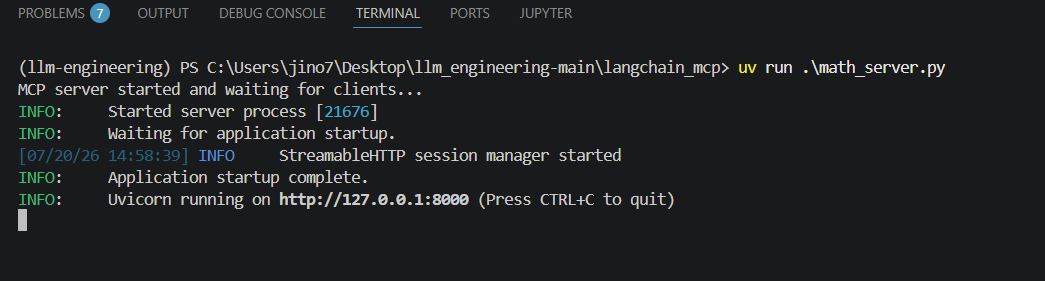

## Using with LangGraph StateGraph

MCP Client

https://github.com/langchain-ai/langchain-mcp-adapters#using-with-langgraph-stategraph


In [5]:
from langchain_mcp_adapters.client import MultiServerMCPClient
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition

from langchain.chat_models import init_chat_model
model = init_chat_model("openai:gpt-5-mini")

client = MultiServerMCPClient(
    {
       "math": {
            # math_server.py는 기본 포트 8000에서 실행 중이어야 함
            "url": "http://localhost:8000/mcp",
            "transport": "streamable_http",
        }
        
    }
)
tools = await client.get_tools()

def call_model(state: MessagesState):
    response = model.bind_tools(tools).invoke(state["messages"])
    return {"messages": response}

builder = StateGraph(MessagesState)
builder.add_node(call_model)
builder.add_node(ToolNode(tools))
builder.add_edge(START, "call_model")
builder.add_conditional_edges(
    "call_model",
    tools_condition,
)
builder.add_edge("tools", "call_model")
graph = builder.compile()



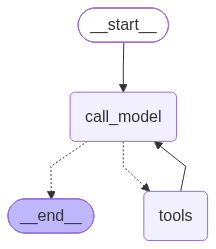

In [6]:
graph 

In [7]:
math_response = await  graph.ainvoke({"messages": "what's (3 + 5) x 12?"})

# 응답에 포함된 메시지들을 순서대로 출력
for m in math_response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what's (3 + 5) x 12?
================================== Ai Message ==================================

(3 + 5) × 12 = 8 × 12 = 96.


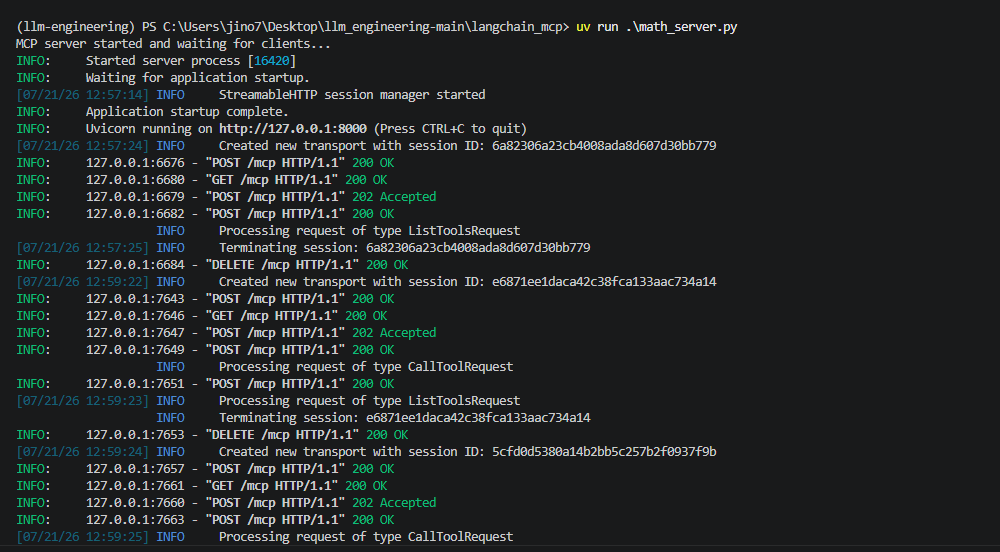

# [예제2] Multiple MCP Servers

https://github.com/langchain-ai/langchain-mcp-adapters#multiple-mcp-servers

# 서버 세팅

##   1번 서버

can add and multiply numbers.

In [ ]:
# math_server.py
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Math"라는 이름의 MCP 서버 인스턴스를 생성
mcp = FastMCP("Math")

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def add(a: int, b: int) -> int:
    """Add two numbers"""  # 두 숫자를 더하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 더한 결과를 반환
    return a + b

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def multiply(a: int, b: int) -> int:
    """Multiply two numbers"""  # 두 숫자를 곱하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 곱한 결과를 반환
    return a * b

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # 서버 시작 안내 메시지를 콘솔에 출력
    print("MCP server started and waiting for clients...")
    # streamable-http 전송 방식으로 MCP 서버를 실행 (기본적으로 http://localhost:8000/mcp 에서 대기)
    mcp.run(transport="streamable-http")

터미날에서 math_server.py 실행



In [ ]:
uv run math_server.py

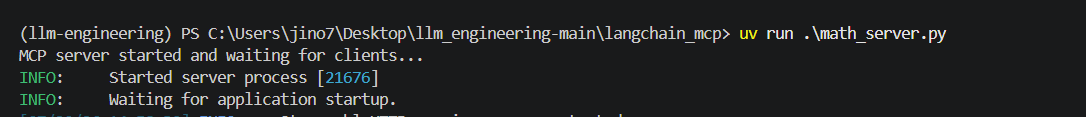

## 2번 서버

In [ ]:
# weather_server.py
# 타입 힌트를 위한 List를 가져옴
from typing import List
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Weather"라는 이름의 MCP 서버 인스턴스를 생성하고, 서버 포트를 8001로 지정
mcp = FastMCP("Weather", port=8001)

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
async def get_weather(location: str) -> str:
    """Get weather for location."""  # 지정한 위치의 날씨를 조회하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 고정된 날씨 문자열을 반환 (실제 API 호출 없이 테스트용 응답)
    return "It's always sunny in New York"

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # http 전송 방식으로 MCP 서버를 실행 (포트 8001에서 대기)
     mcp.run(transport="streamable-http")

서버 실행

In [ ]:
uv run weather_server.py 

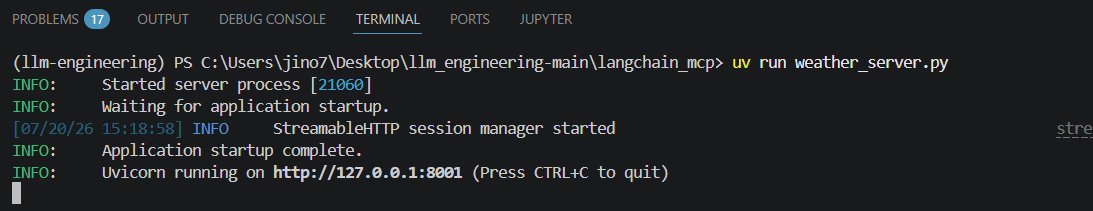

# MCP 클라이언트 

In [8]:
from langchain_mcp_adapters.client import MultiServerMCPClient
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition

from langchain.chat_models import init_chat_model
model = init_chat_model("openai:gpt-4.1")

client = MultiServerMCPClient(
    {
      "math": {
            # math_server.py는 기본 포트 8000에서 실행 중이어야 함
            "url": "http://localhost:8000/mcp",
            "transport": "streamable_http",
        },
        "weather": {
            # make sure you start your weather server on port 8000
            "url": "http://localhost:8001/mcp",
            "transport": "http",
        }
    }
)
tools = await client.get_tools()

def call_model(state: MessagesState):
    response = model.bind_tools(tools).invoke(state["messages"])
    return {"messages": response}

builder = StateGraph(MessagesState)
builder.add_node(call_model)
builder.add_node(ToolNode(tools))
builder.add_edge(START, "call_model")
builder.add_conditional_edges(
    "call_model",
    tools_condition,
)
builder.add_edge("tools", "call_model")
graph = builder.compile()



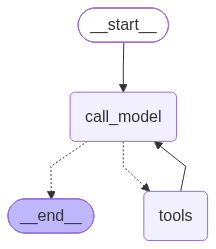

In [9]:
graph 

In [11]:

# math 서버 도구를 사용하는 질문을 에이전트에 전달하고 응답을 받음
math_response = await graph.ainvoke({"messages": "what's (3 + 5) x 12?"})
# 응답에 포함된 메시지들을 순서대로 출력
for m in math_response["messages"]:
    m.pretty_print()

# weather 서버 도구를 사용하는 질문을 에이전트에 전달하고 응답을 받음
weather_response = await graph.ainvoke({"messages": "what is the weather in nyc?"})
# 응답에 포함된 메시지들을 순서대로 출력
for m in weather_response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what's (3 + 5) x 12?
================================== Ai Message ==================================
Tool Calls:
  add (call_pdqdyOya3o9AYbni3Hw91yco)
 Call ID: call_pdqdyOya3o9AYbni3Hw91yco
  Args:
    a: 3
    b: 5
================================= Tool Message =================================
Name: add

[{'type': 'text', 'text': '8', 'id': 'lc_0cf99b05-1e8c-4783-8d01-9b006a1a92e6'}]
================================== Ai Message ==================================
Tool Calls:
  multiply (call_EYzErYGz3uvyhyCPYyoUPxsE)
 Call ID: call_EYzErYGz3uvyhyCPYyoUPxsE
  Args:
    a: 8
    b: 12
================================= Tool Message =================================
Name: multiply

[{'type': 'text', 'text': '96', 'id': 'lc_ce4eb46c-2e6d-4261-8cf3-c53fae7ccbef'}]
================================== Ai Message ==================================

(3 + 5) x 12 equals 96.
================================ Human 